# 02 - ERP and P300 Analysis

Goal: extract and quantify the auditory P300 response for standard and oddball stimuli.

In [1]:
from pathlib import Path
import mne
import matplotlib.pyplot as plt

In [3]:
DATA_ROOT = Path(
    r"C:\Users\Fafou\Desktop\Postdoc_UBC\code\EEG_project"
    r"\project1_openneuro\data\ds003061"
)

eeg_file = DATA_ROOT / "sub-001" / "eeg" / "sub-001_task-P300_run-1_eeg.set"

raw = mne.io.read_raw_eeglab(
    eeg_file,
    preload=True
)

print(raw)

C:\Users\Fafou\AppData\Local\Temp\ipykernel_35452\2590537075.py:8: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(


<RawEEGLAB | sub-001_task-P300_run-1_eeg.set, 79 x 194048 (758.0 s), ~117.0 MiB, data loaded>


C:\Users\Fafou\AppData\Local\Temp\ipykernel_35452\2590537075.py:8: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(


In [4]:
raw_clean = raw.copy()

In [5]:
raw_clean.set_eeg_reference("average")

raw_clean.filter(
    l_freq=1.0,
    h_freq=None
)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 845 samples (3.301 s)



<RawEEGLAB | sub-001_task-P300_run-1_eeg.set, 79 x 194048 (758.0 s), ~117.0 MiB, data loaded>

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


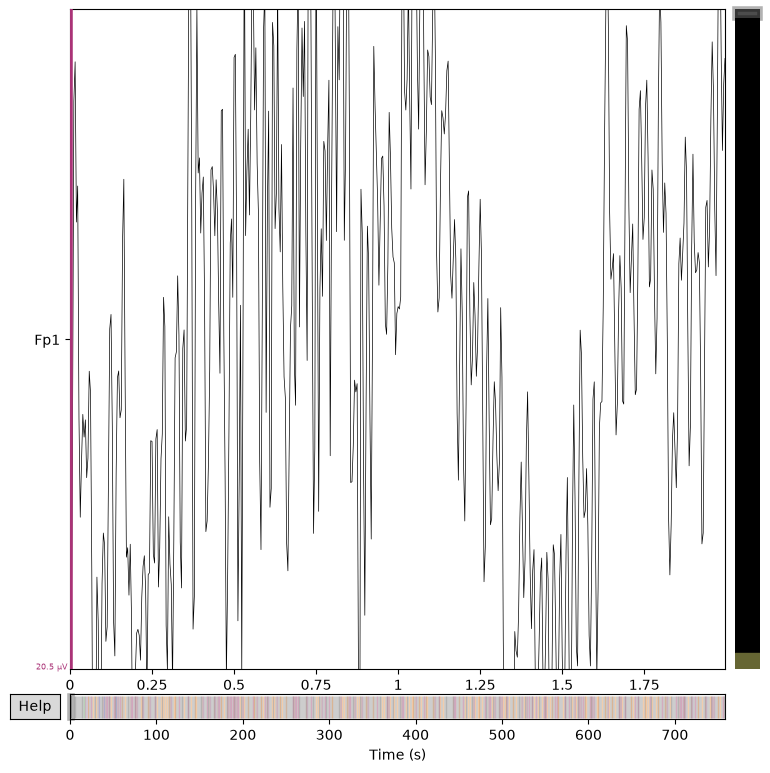

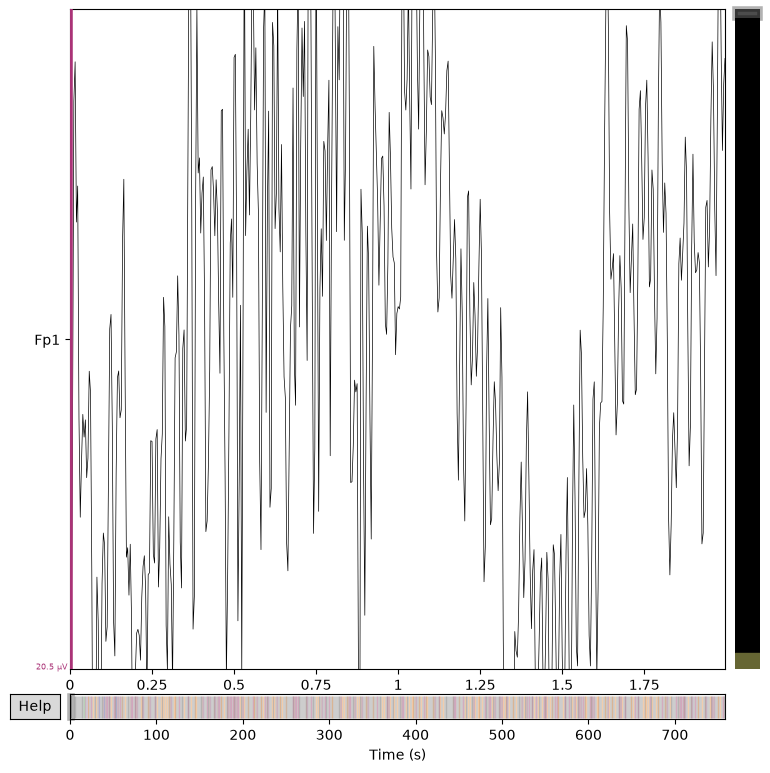

In [13]:
raw_clean.plot(
    duration=2,
    n_channels=1,
    scalings="auto"
)

In [27]:
picks = ["Fp1", "Fz", "Cz", "Pz", "Oz"]

start = 0
duration = 1

data, times = raw_clean[picks, int(start * raw_clean.info["sfreq"]):
                              int((start + duration) * raw_clean.info["sfreq"])]

data = data * 1e6

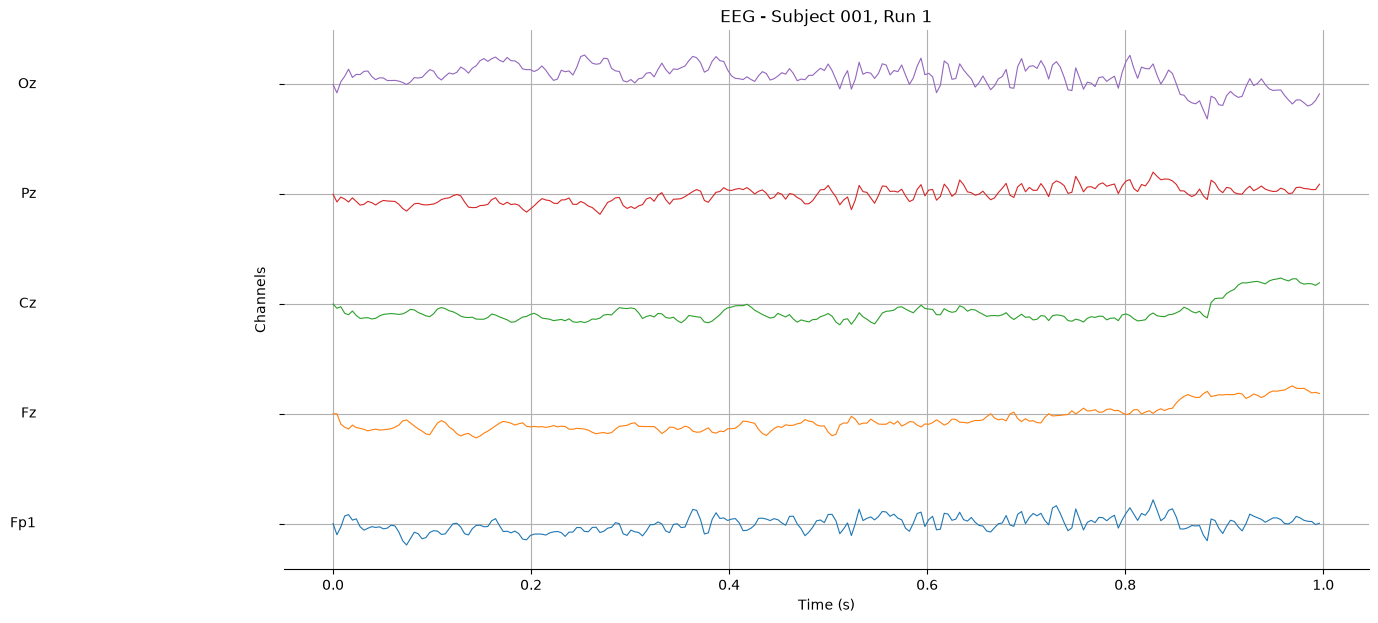

In [28]:
fig, ax = plt.subplots(figsize=(14, 7))

offset = 100

for i, channel in enumerate(picks):
    ax.plot(times, data[i] + i * offset, linewidth=0.8)
    ax.text(times[0] - 0.3, i * offset, channel, ha="right", va="center")

ax.set_xlabel("Time (s)")
ax.set_ylabel("Channels")
ax.set_title("EEG - Subject 001, Run 1")
ax.set_yticks([])
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_yticks([i * offset for i in range(len(picks))])
ax.set_yticklabels([])
ax.grid(visible=True, axis="y")
ax.grid(visible=True)

plt.show()

In [29]:
events, event_id = mne.events_from_annotations(raw_clean)

print(event_id)

Used Annotations descriptions: ['ignore', 'noise', 'noise_with_reponse', 'oddball', 'oddball_with_reponse', 'response', 'standard']
{'ignore': 1, 'noise': 2, 'noise_with_reponse': 3, 'oddball': 4, 'oddball_with_reponse': 5, 'response': 6, 'standard': 7}


In [32]:
epochs = mne.Epochs(
    raw_clean,
    events,
    event_id={
        "standard": event_id["standard"],
        "oddball/no_response": event_id["oddball"],
        "oddball/response": event_id["oddball_with_reponse"],
    },
    tmin=-0.2,
    tmax=0.8,
    baseline=(-0.2, 0),
    preload=True
)

print("Standard:", len(epochs["standard"]))
print("Oddball:", len(epochs["oddball"]))

Not setting metadata
635 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 635 events and 257 original time points ...
1 bad epochs dropped
Standard: 521
Oddball: 113


Used Annotations descriptions: ['ignore', 'noise', 'noise_with_reponse', 'oddball', 'oddball_with_reponse', 'response', 'standard']
Event IDs:
{'ignore': 1, 'noise': 2, 'noise_with_reponse': 3, 'oddball': 4, 'oddball_with_reponse': 5, 'response': 6, 'standard': 7}
Not setting metadata
635 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 635 events and 257 original time points ...
1 bad epochs dropped
Standard epochs: 521
Oddball epochs: 113


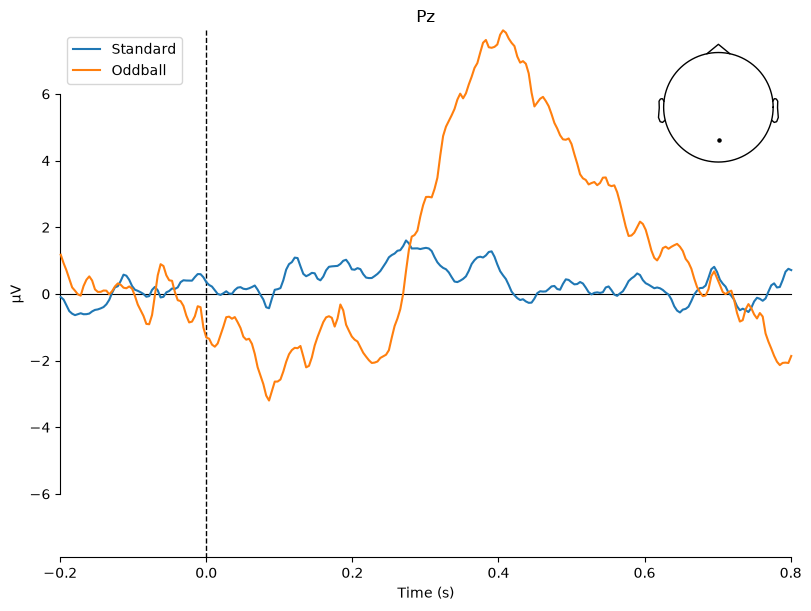

[<Figure size 800x600 with 2 Axes>]

In [38]:
# Convert annotations such as "standard" and "oddball"
# into numerical event markers that MNE can use.
events, event_id = mne.events_from_annotations(raw_clean)

print("Event IDs:")
print(event_id)


# Cut the continuous EEG into epochs around standard and oddball stimuli.
epochs = mne.Epochs(
    raw_clean,
    events,
    event_id={
        "standard": event_id["standard"],
        "oddball/no_response": event_id["oddball"],
        "oddball/response": event_id["oddball_with_reponse"],
    },
    tmin=-0.2,              # Start 200 ms before stimulus
    tmax=0.8,               # End 800 ms after stimulus
    baseline=(-0.2, 0),     # Baseline-correct using pre-stimulus period
    preload=True            # Load epochs into memory
)


# Check how many trials we have for each condition.
print("Standard epochs:", len(epochs["standard"]))
print("Oddball epochs:", len(epochs["oddball"]))


# Average individual trials to obtain ERPs.
standard_erp = epochs["standard"].average()
oddball_erp = epochs["oddball"].average()


# Compare standard and oddball ERPs at electrode Pz.
mne.viz.plot_compare_evokeds(
    {
        "Standard": standard_erp,
        "Oddball": oddball_erp
    },
    picks="Pz",
    show_sensors=True
)

P300 channel: Pz
P300 latency: 421.9 ms
P300 amplitude: 7.47 µV


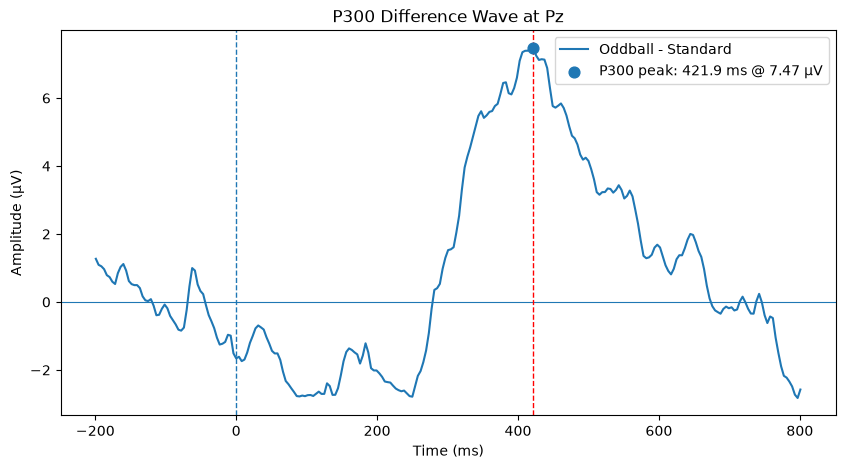

In [45]:
# Create an oddball-minus-standard difference ERP.
difference_erp = mne.combine_evoked(
    [oddball_erp, standard_erp],
    weights=[1, -1]
)

# Keep only electrode Pz for P300 peak analysis.
pz_difference = difference_erp.copy().pick(["Pz"])

# Find the largest positive peak between 250 and 500 ms.
channel, latency, amplitude = pz_difference.get_peak(
    tmin=0.25,
    tmax=0.50,
    mode="pos",
    return_amplitude=True
)

# Convert MNE units into milliseconds and microvolts.
latency_ms = latency * 1000
amplitude_uv = amplitude * 1e6

# Print P300 measurements.
print("P300 channel:", channel)
print("P300 latency:", round(latency_ms, 1), "ms")
print("P300 amplitude:", round(amplitude_uv, 2), "µV")

# Prepare waveform for plotting.
times_ms = pz_difference.times * 1000
signal_uv = pz_difference.data[0] * 1e6

# Plot the difference waveform and mark the detected P300 peak.
plt.figure(figsize=(10, 5))

plt.plot(times_ms, signal_uv, label="Oddball - Standard")
plt.axvline(0, linestyle="--", linewidth=1)
plt.axhline(0, linewidth=0.8)
plt.axvline(latency_ms, linestyle="--", linewidth=1,color="red")

plt.scatter(
    latency_ms,
    amplitude_uv,
    s=60,
    zorder=3,
    label=f"P300 peak: {latency_ms:.1f} ms @ {amplitude_uv:.2f} µV"
)



plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (µV)")
plt.title("P300 Difference Wave at Pz")
plt.legend()

plt.show()

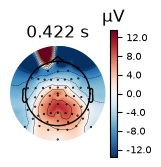

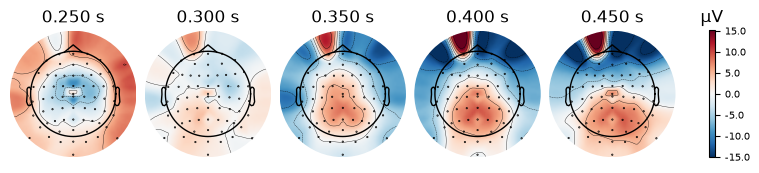

combining channels using GFP (eeg channels)
combining channels using GFP (eeg channels)


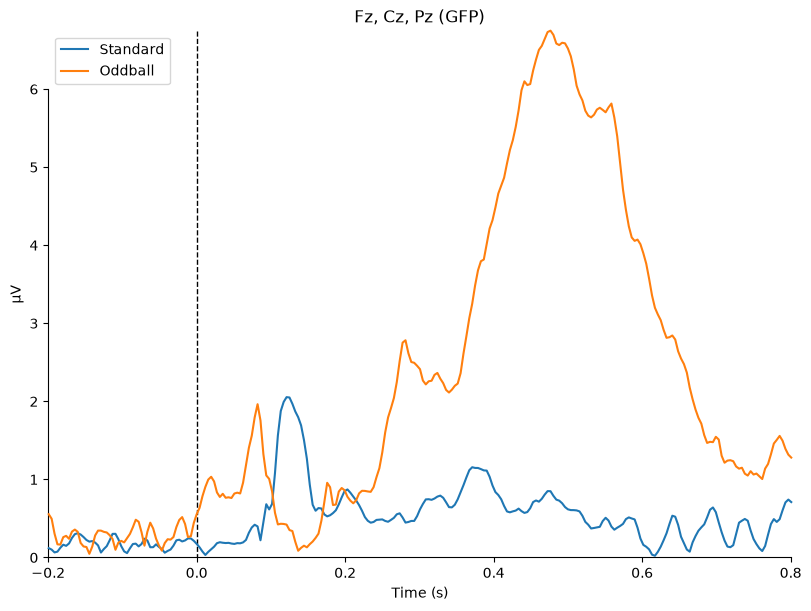

No projector specified for this dataset. Please consider the method self.add_proj.


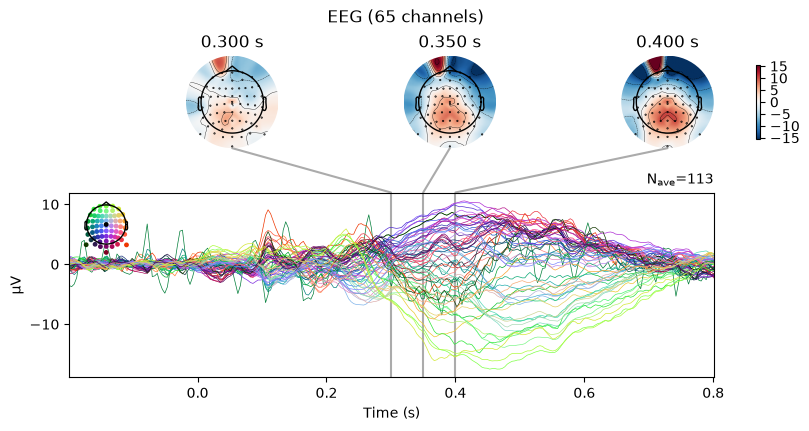

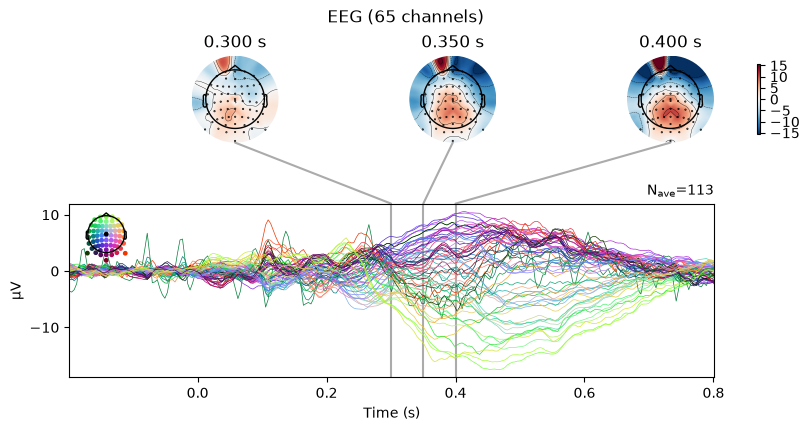

In [46]:
# ---------------------------------------------------------
# P300 scalp topography
# ---------------------------------------------------------

# Plot the spatial voltage distribution at the automatically
# detected P300 peak latency.
difference_erp.plot_topomap(
    times=[latency]
)


# ---------------------------------------------------------
# See how the spatial pattern evolves over time
# ---------------------------------------------------------

# Plot scalp maps from 250 to 450 ms after stimulus onset.
difference_erp.plot_topomap(
    times=[0.25, 0.30, 0.35, 0.40, 0.45]
)


# ---------------------------------------------------------
# Compare ERP waveforms along the midline
# ---------------------------------------------------------

mne.viz.plot_compare_evokeds(
    {
        "Standard": standard_erp,
        "Oddball": oddball_erp
    },
    picks=["Fz", "Cz", "Pz"]
)


# ---------------------------------------------------------
# Combined waveform + scalp topography figure
# ---------------------------------------------------------

oddball_erp.plot_joint(
    times=[0.30, 0.35, 0.40]
)

In [51]:
import numpy as np
import pandas as pd


def extract_subject_p300(subject):
    """
    Extract participant-level P300 features across all available runs.

    Event codes are normalized across recordings:
        standard = 1
        oddball  = 2

    This prevents differences in original EEGLAB event numbering
    from causing problems when epochs from different runs are combined.
    """

    # Find all EEG .set files for this participant.
    eeg_files = sorted(
        (DATA_ROOT / subject / "eeg").glob("*_eeg.set")
    )

    # Containers for epochs from each run.
    standard_epochs_runs = []
    oddball_epochs_runs = []

    # Process each run separately.
    for eeg_file in eeg_files:

        print("  ", eeg_file.name)

        # -------------------------------------------------
        # Load continuous EEG
        # -------------------------------------------------

        raw = mne.io.read_raw_eeglab(
            eeg_file,
            preload=True,
            verbose=False
        )

        # Common-average reference.
        raw.set_eeg_reference(
            "average",
            verbose=False
        )

        # Remove slow drifts below 1 Hz.
        raw.filter(
            l_freq=1.0,
            h_freq=None,
            verbose=False
        )

        # -------------------------------------------------
        # Read event annotations
        # -------------------------------------------------

        events, event_id = mne.events_from_annotations(
            raw,
            verbose=False
        )

        # -------------------------------------------------
        # STANDARD EVENTS
        # -------------------------------------------------

        # Find whichever numerical code means "standard"
        # in this particular recording.
        standard_code = event_id["standard"]

        # Select only standard events.
        standard_events = events[
            events[:, 2] == standard_code
        ].copy()

        # Normalize their code:
        # standard will ALWAYS equal 1 in our analysis.
        standard_events[:, 2] = 1

        # -------------------------------------------------
        # ODDBALL EVENTS
        # -------------------------------------------------

        # Find whichever oddball event types exist in this run.
        oddball_codes = []

        if "oddball" in event_id:
            oddball_codes.append(
                event_id["oddball"]
            )

        if "oddball_with_reponse" in event_id:
            oddball_codes.append(
                event_id["oddball_with_reponse"]
            )

        # Safety check:
        # every recording should contain oddball stimuli.
        if len(oddball_codes) == 0:
            raise ValueError(
                f"No oddball events found in {eeg_file.name}"
            )

        # Select all events whose code corresponds
        # to either type of oddball.
        oddball_events = events[
            np.isin(events[:, 2], oddball_codes)
        ].copy()

        # Normalize their code:
        # oddball will ALWAYS equal 2 in our analysis.
        oddball_events[:, 2] = 2

        # -------------------------------------------------
        # CREATE EPOCHS
        # -------------------------------------------------

        standard_epochs = mne.Epochs(
            raw,
            standard_events,
            event_id={"standard": 1},
            tmin=-0.2,
            tmax=0.8,
            baseline=(-0.2, 0),
            preload=True,
            verbose=False
        )

        oddball_epochs = mne.Epochs(
            raw,
            oddball_events,
            event_id={"oddball": 2},
            tmin=-0.2,
            tmax=0.8,
            baseline=(-0.2, 0),
            preload=True,
            verbose=False
        )

        # Store this run's epochs.
        standard_epochs_runs.append(
            standard_epochs
        )

        oddball_epochs_runs.append(
            oddball_epochs
        )

    # -------------------------------------------------
    # COMBINE ALL RUNS
    # -------------------------------------------------

    standard_epochs = mne.concatenate_epochs(
        standard_epochs_runs
    )

    oddball_epochs = mne.concatenate_epochs(
        oddball_epochs_runs
    )

    # -------------------------------------------------
    # COMPUTE ERPs
    # -------------------------------------------------

    standard_erp = standard_epochs.average()

    oddball_erp = oddball_epochs.average()

    # Oddball minus standard difference ERP.
    difference_erp = mne.combine_evoked(
        [oddball_erp, standard_erp],
        weights=[1, -1]
    )

    # -------------------------------------------------
    # P300 AT Pz
    # -------------------------------------------------

    pz = difference_erp.copy().pick(["Pz"])

    # Find the largest positive peak
    # between 250 and 500 ms.
    channel, latency, amplitude = pz.get_peak(
        tmin=0.25,
        tmax=0.50,
        mode="pos",
        return_amplitude=True
    )

    # Convert seconds -> ms
    # and volts -> microvolts.
    latency_ms = latency * 1000
    amplitude_uv = amplitude * 1e6

    # Return participant-level measurements.
    return {
        "subject": subject,
        "n_standard": len(standard_epochs),
        "n_oddball": len(oddball_epochs),
        "p300_latency_ms": latency_ms,
        "p300_amplitude_uv": amplitude_uv,
    }


# ---------------------------------------------------------
# RUN ALL PARTICIPANTS
# ---------------------------------------------------------

subjects = sorted(DATA_ROOT.glob("sub-*"))

results = []

for subject_path in subjects:

    subject = subject_path.name

    print("\nProcessing:", subject)

    result = extract_subject_p300(subject)

    results.append(result)


# ---------------------------------------------------------
# CREATE RESULTS TABLE
# ---------------------------------------------------------

p300_results = pd.DataFrame(results)

p300_results["p300_latency_ms"] = (
    p300_results["p300_latency_ms"].round(1)
)

p300_results["p300_amplitude_uv"] = (
    p300_results["p300_amplitude_uv"].round(2)
)

p300_results


Processing: sub-001
   sub-001_task-P300_run-1_eeg.set


C:\Users\Fafou\AppData\Local\Temp\ipykernel_35452\822903196.py:35: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_35452\822903196.py:35: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(


   sub-001_task-P300_run-2_eeg.set


C:\Users\Fafou\AppData\Local\Temp\ipykernel_35452\822903196.py:35: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_35452\822903196.py:35: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(


   sub-001_task-P300_run-3_eeg.set


...

   sub-013_task-P300_run-3_eeg.set


C:\Users\Fafou\AppData\Local\Temp\ipykernel_35452\822903196.py:35: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_35452\822903196.py:35: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(


Not setting metadata
1577 matching events found
No baseline correction applied
Not setting metadata
334 matching events found
No baseline correction applied


C:\Users\Fafou\AppData\Local\Temp\ipykernel_35452\822903196.py:153: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  standard_epochs = mne.concatenate_epochs(
C:\Users\Fafou\AppData\Local\Temp\ipykernel_35452\822903196.py:157: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  oddball_epochs = mne.concatenate_epochs(


,subject,n_standard,n_oddball,p300_latency_ms,p300_amplitude_uv
0,sub-001,1571,334,378.9,8.94
1,sub-002,1550,334,437.5,4.63
2,sub-003,1541,336,433.6,5.57
3,sub-004,1568,333,488.3,3.38
4,sub-005,1560,332,437.5,5.13
5,sub-006,1594,338,367.2,10.79
6,sub-007,1533,336,429.7,3.38
7,sub-008,1523,333,500.0,2.65
8,sub-009,1577,336,386.7,7.97
9,sub-010,1571,335,367.2,9.19
